## Loading Gaze Patch Datasets

After conversion, we need to load the newly created gaze patch datasets into pytorch datasets.

In [ ]:
import fovealgat_confs as conf

### REFLACX

In [3]:
from reflacx import ReflacxGazePatchDataset

In [4]:
gaze_dataset_pth = conf.reflacx_gaze_dataset_pth
desired_label = 'Atelectasis'

In [5]:
ds = ReflacxGazePatchDataset(gaze_dataset_pth, desired_label)

In [6]:
fs, gsp, labels = ds[33]

In [7]:
import matplotlib.pyplot as plt

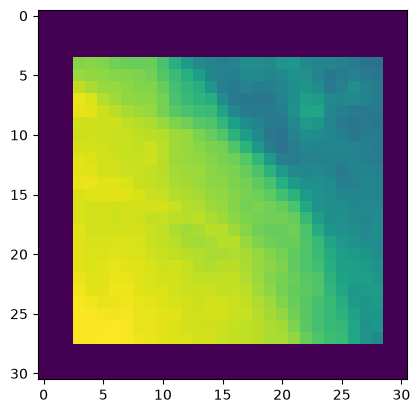

In [8]:
plt.imshow(gsp[13])

to make a data loader, we first need a collate function, as the gaze patch sequences vary in size

In [9]:
from dataset_tools import gaze_patch_dataset_collate

In [10]:
ls, fs, ps, labels = gaze_patch_dataset_collate((ds[33], ds[34], ds[0]))

In [11]:
ls, sum(ls)

([47, 155, 53], 255)

In [12]:
fs.shape, ps.shape, labels.shape

(torch.Size([255, 3, 1, 1]), torch.Size([255, 1, 31, 31]), torch.Size([3]))

now for the DataLoader itself

In [13]:
from torch.utils.data import DataLoader

In [14]:
loader = DataLoader(ds,
                    batch_size=6,
                    collate_fn=gaze_patch_dataset_collate,
                    num_workers=4,
                    pin_memory=True)

In [15]:
b = None
for batch in loader:
    b = batch
    break

In [16]:
ls, fs, ps, labels = b

In [17]:
ls, sum(ls)

([53, 95, 214, 335, 112, 89], 898)

In [18]:
fs.shape, ps.shape, labels.shape

(torch.Size([898, 3, 1, 1]), torch.Size([898, 1, 31, 31]), torch.Size([6]))

### MIMIC EYE (Not used in the publication)

In [ ]:
from matplotlib import pyplot as plt

In [ ]:
from mimic_eye import MimicEyeGazePatchDataset

In [ ]:
gaze_dataset_pth = conf.mimic_gaze_dataset_pth
desired_label = 'pneumonia'

In [ ]:
ds = MimicEyeGazePatchDataset(gaze_dataset_pth, desired_label)

In [ ]:
fs, gsp, labels = ds[33]

In [ ]:
fs.shape, gsp.shape, labels.shape

In [ ]:
plt.imshow(gsp[7])

now for the data loader, identical to the reflacx case

In [ ]:
from torch.utils.data import DataLoader

from dataset_tools import gaze_patch_dataset_collate

In [ ]:
loader = DataLoader(ds,
                    batch_size=6,
                    collate_fn=gaze_patch_dataset_collate,
                    num_workers=4,
                    pin_memory=True)

In [ ]:
b = None
for batch in loader:
    b = batch
    break

In [ ]:
ls, fs, ps, labels = b

In [ ]:
ls, sum(ls)

In [ ]:
fs.shape, ps.shape, labels.shape